# Chapter 11: Novelty and Outlier Detection

**Book:** *scikit-learn Cookbook, Third Edition* – John Sukup  
**Chapter summary and practical examples**

This notebook paraphrases the chapter's key ideas and demonstrates the three principal detectors with small, reproducible scikit-learn examples.

## Learning Objectives

By the end of this notebook, you should be able to:

- Distinguish **outliers** in the training data from **novelties** encountered later.
- Use Isolation Forest, One-Class SVM, and Local Outlier Factor (LOF).
- Interpret common prediction labels and anomaly scores.
- Evaluate anomaly detectors when reference labels are available.
- Decide what to do with flagged observations and choose a method that fits the data.

## Environment Setup

The examples use synthetic data so the anomaly patterns are known and easy to visualize. In real applications, the definition of an anomaly should also reflect domain knowledge.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix

RANDOM_STATE = 2024


## 11.1 Outlier Detection and Novelty Detection

An **outlier** is an observation that differs markedly from other observations in the dataset being examined. A **novelty** is an unfamiliar observation that appears after a model has learned the pattern of normal training data. These are related but not identical tasks: some detectors are designed to identify anomalies within a dataset, while novelty detectors learn a boundary from normal examples and score new observations later.

The `contamination` setting in some estimators represents an expected outlier proportion and affects the decision threshold. Scaling features is particularly important for methods that rely on distances or kernels.

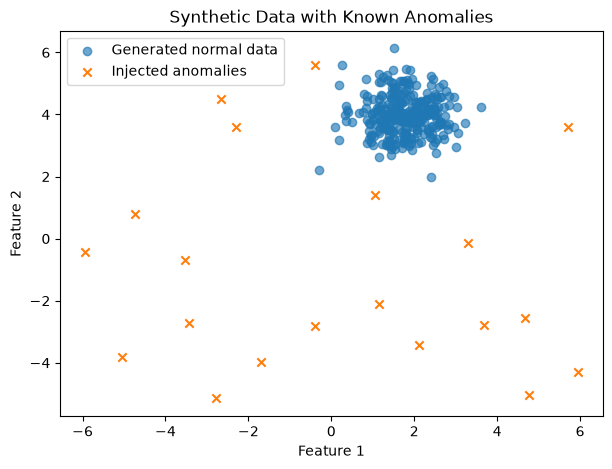

In [2]:
X_normal, _ = make_blobs(
    n_samples=300, centers=1, cluster_std=0.60, random_state=RANDOM_STATE
)
rng = np.random.default_rng(RANDOM_STATE)
X_outliers = rng.uniform(low=-6, high=6, size=(20, 2))
X_all = np.vstack([X_normal, X_outliers])
y_true = np.r_[np.ones(len(X_normal)), -np.ones(len(X_outliers))]

plt.figure(figsize=(7, 5))
plt.scatter(X_normal[:, 0], X_normal[:, 1], label="Generated normal data", alpha=0.65)
plt.scatter(X_outliers[:, 0], X_outliers[:, 1], label="Injected anomalies", marker="x")
plt.title("Synthetic Data with Known Anomalies")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.show()


## 11.2 Isolation Forest

Isolation Forest detects unusual observations by repeatedly selecting features and random split points. Anomalies often become isolated after fewer splits, so their average path lengths through the trees tend to be shorter. It is relatively scalable and does not depend directly on a distance or density calculation.

In scikit-learn, `predict()` returns `1` for inliers and `-1` for outliers. `contamination` helps set the expected anomaly fraction; it should be chosen carefully rather than treated as a known truth.

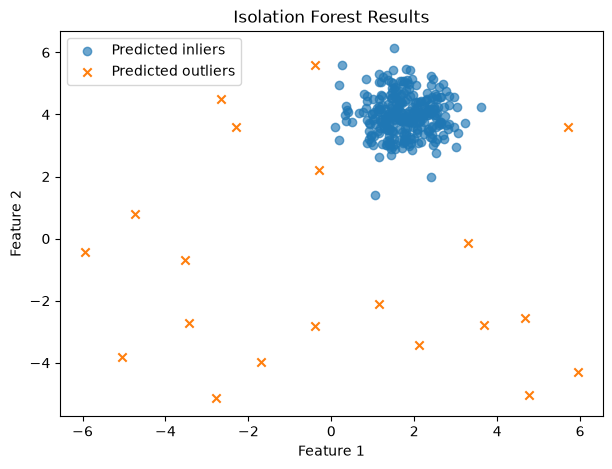

Five lowest (most anomalous) scores: [-0.15737501 -0.15431344 -0.13908715 -0.13819331 -0.13510653]


In [3]:
iso = IsolationForest(
    n_estimators=100, contamination=0.06, random_state=RANDOM_STATE
)
iso_labels = iso.fit_predict(X_all)

plt.figure(figsize=(7, 5))
plt.scatter(X_all[iso_labels == 1, 0], X_all[iso_labels == 1, 1],
            label="Predicted inliers", alpha=0.65)
plt.scatter(X_all[iso_labels == -1, 0], X_all[iso_labels == -1, 1],
            label="Predicted outliers", marker="x")
plt.title("Isolation Forest Results")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.show()

# Lower decision_function values indicate more anomalous observations.
scores = iso.decision_function(X_all)
print("Five lowest (most anomalous) scores:", np.sort(scores)[:5])


## 11.3 One-Class SVM for Novelty Detection

One-Class SVM learns a boundary around the normal training observations. New points outside that learned region are treated as novelties. Its kernel option allows nonlinear boundaries; the RBF kernel is a common starting point. The `nu` parameter influences the allowed fraction of training errors and support vectors.

For novelty detection, fit the model on normal training data only, then use `predict()` on separate test observations. Standardizing features is usually important for this kernel-based method.

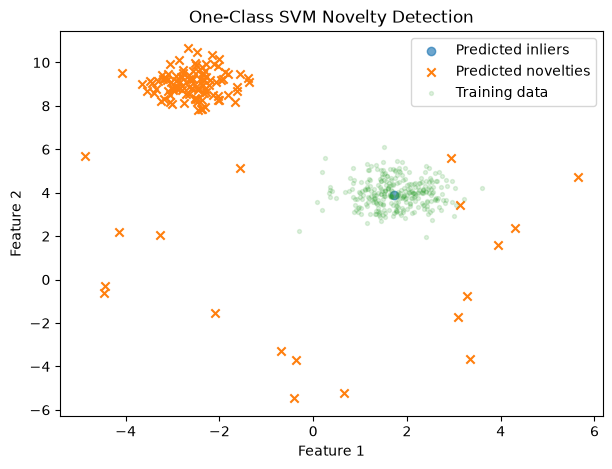

In [4]:
# Fit using only normal examples, then evaluate a separate set containing novelties.
X_train, _ = make_blobs(
    n_samples=300, centers=1, cluster_std=0.60, random_state=RANDOM_STATE
)
X_test_normal, _ = make_blobs(
    n_samples=100, centers=1, cluster_std=0.60, random_state=42
)
X_test_novel = np.random.default_rng(42).uniform(-6, 6, size=(20, 2))
X_test = np.vstack([X_test_normal, X_test_novel])

scaler = StandardScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

ocsvm = OneClassSVM(kernel="rbf", gamma="scale", nu=0.05)
ocsvm.fit(X_train_scaled)
novelty_pred = ocsvm.predict(X_test_scaled)

plt.figure(figsize=(7, 5))
plt.scatter(X_test[novelty_pred == 1, 0], X_test[novelty_pred == 1, 1],
            label="Predicted inliers", alpha=0.65)
plt.scatter(X_test[novelty_pred == -1, 0], X_test[novelty_pred == -1, 1],
            label="Predicted novelties", marker="x")
plt.scatter(X_train[:, 0], X_train[:, 1], s=8, alpha=0.15, label="Training data")
plt.title("One-Class SVM Novelty Detection")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.show()


## 11.4 Detecting Outliers with Local Outlier Factor (LOF)

LOF compares a point's local density with the density around its neighbors. A point located in a much sparser region than nearby observations may receive an outlier label. This local comparison can detect unusual points that are not simply far away from the entire dataset.

By default, LOF is commonly used to detect outliers in the data passed to `fit_predict()`. To score future unseen data, configure it with `novelty=True`, fit on the normal training set, and then call `predict()` on new observations.

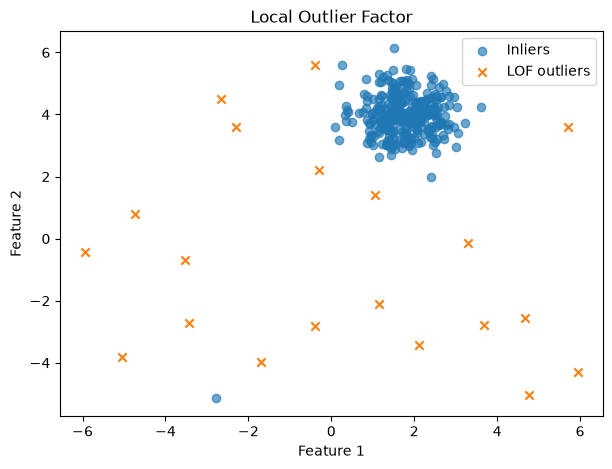

In [5]:
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.06)
lof_labels = lof.fit_predict(X_all)

plt.figure(figsize=(7, 5))
plt.scatter(X_all[lof_labels == 1, 0], X_all[lof_labels == 1, 1],
            label="Inliers", alpha=0.65)
plt.scatter(X_all[lof_labels == -1, 0], X_all[lof_labels == -1, 1],
            label="LOF outliers", marker="x")
plt.title("Local Outlier Factor")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.show()


## 11.5 Evaluating Outlier Detection Models

When synthetic data or expert review provides ground-truth labels, anomaly detection can be evaluated like a binary classification problem. Here, the anomaly class is mapped to `1` and normal observations to `0`. Precision measures how many flagged observations are truly anomalous; recall measures how many known anomalies are found. The F1-score combines the two.

In real unsupervised settings, reliable labels may not exist. In that case, use careful visual inspection, domain validation, stability checks, and follow-up investigations rather than relying on a single metric.

In [6]:
# Convert scikit-learn labels: -1 = anomaly, 1 = normal.
y_true_binary = (y_true == -1).astype(int)
y_pred_binary = (iso_labels == -1).astype(int)

print(confusion_matrix(y_true_binary, y_pred_binary))
print(classification_report(
    y_true_binary, y_pred_binary,
    target_names=["normal", "anomaly"], zero_division=0
))


[[299   1]
 [  1  19]]
              precision    recall  f1-score   support

      normal       1.00      1.00      1.00       300
     anomaly       0.95      0.95      0.95        20

    accuracy                           0.99       320
   macro avg       0.97      0.97      0.97       320
weighted avg       0.99      0.99      0.99       320



## 11.6 Handling Detected Outliers

A detector's label is a signal for investigation, not automatic proof that a record is wrong. Depending on the application, a flagged row can be:

- **Checked and corrected** if it reflects a data-entry or measurement error.
- **Kept** if it is a valid rare case that the model should learn to handle.
- **Excluded from a particular analysis** when justified and documented.
- **Sent for review or alerting** in fraud, safety, or monitoring workflows.

Do not remove observations solely because an algorithm flags them. Validate the cause and preserve an audit trail. Also check whether scaling, feature construction, or an incorrect contamination assumption is driving the result.

In [7]:
# Example of creating a review table rather than deleting flagged records.
import pandas as pd

review = pd.DataFrame(X_all, columns=["feature_1", "feature_2"])
review["detector_label"] = iso_labels
review["anomaly_score"] = scores
review["needs_review"] = review["detector_label"].eq(-1)
review.sort_values("anomaly_score").head(10)


,feature_1,feature_2,detector_label,anomaly_score,needs_review
307,-5.944444,-0.418570,-1,-0.157375,True
302,5.949625,-4.293218,-1,-0.154313,True
303,-5.055294,-3.830114,-1,-0.139087,True
319,4.778728,-5.051588,-1,-0.138193,True
314,-2.783246,-5.149419,-1,-0.135107,True
306,-4.735372,0.788773,-1,-0.114258,True
308,5.707466,3.593141,-1,-0.110445,True
304,-1.684237,-3.964569,-1,-0.105929,True
310,-3.523873,-0.687293,-1,-0.099387,True
312,-3.442112,-2.709060,-1,-0.092342,True


## 11.7 Choosing the Right Detection Technique

| Method | Main idea | Useful situations | Important considerations |
|---|---|---|---|
| Isolation Forest | Randomly isolates observations | Larger or higher-dimensional datasets | Tune expected contamination; inspect scores |
| One-Class SVM | Learns a boundary around normal training data | Novelty detection when normal examples are available | Sensitive to scaling and kernel settings |
| LOF | Compares local density with neighboring points | Local anomalies in data with varying density | Choose neighborhood size; distinguish outlier and novelty modes |

There is no universally best detector. Compare methods on representative data, scale features when appropriate, and validate flagged cases with knowledge of the application.

## Practical Workflow

1. Inspect and visualize the data before choosing an algorithm.
2. Clean obvious data-quality problems and consider feature scaling.
3. Decide whether the task is outlier detection or novelty detection.
4. Fit one or more suitable estimators and inspect their predictions or scores.
5. Tune parameters such as `contamination`, `nu`, or `n_neighbors`.
6. Validate flagged observations and document how they are handled.
7. Monitor for distribution changes when the detector is used in production.

## Chapter 11 Summary

Outlier and novelty detection help identify observations that differ from expected patterns. Isolation Forest uses random partitioning, One-Class SVM learns a boundary from normal examples, and LOF compares local densities. Model choice depends on the data structure and use case. Scores and labels should guide investigation; they should not replace domain validation or careful decisions about whether to retain, correct, or exclude observations.